In [1]:
import os
import re
import glob
import json
import subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr

In [2]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
USERNAME = "nocturnalnerd18"
OUT_DIR = "/kaggle/working/patch_qwen_analysis"
os.makedirs(OUT_DIR, exist_ok=True)

N_LAYER, N_HEAD = 28, 28
GROUPS = ["visual", "text", "tail"]
DIRECTIONS = ["noising", "denoising"]

MIN_GROUP = 10
MIN_BIN = 5
N_PERM = 500
K_TOP = 20
MIN_LOGITS = 0.05
DRIVEN_TE = -1.0
UNIT_BINS = {"attribute": 3, "relation/reefknot": 8, "relation/amber": 3}
CONTRASTS = {
    "evidence": ("false_yes", "true_yes", 1, None),
    "evidence_matched": ("false_yes", "true_yes", 0, None),
    "matched_driven": ("false_yes", "true_yes", 0, "driven"),
}
UNITS = {
    "attribute": ("attribute", None),
    "relation/reefknot": ("relation", "reefknot"),
    "relation/amber": ("relation", "amber"),
}
SURVIVOR_CONTRASTS = ["evidence_matched", "matched_driven"]


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


def load_stage(tag):
    out, seen = [], set()
    paths = sorted(glob.glob(f"/kaggle/input/**/{tag}_batch_*.pt", recursive=True), key=lambda p: (os.path.dirname(p), batch_number(p)))
    for path in paths:
        for e in torch.load(path):
            if e["question_id"] not in seen:
                seen.add(e["question_id"])
                out.append(e)
    return out


def cell_name(c):
    base = f"L{c['layer']} H{c['head']}" if c["kind"] == "head" else f"L{c['layer']} MLP"
    return f"{base} {c['group']}"


with open(f"{INPUT}/patch-qwen-exact/cells_A.json") as f:
    cells_A = json.load(f)
names_A = [cell_name(c) for c in cells_A]
entries_A = [e for e in load_stage("A") if e["ok"]]
assert entries_A, "attach patch-qwen-exact with stage A entries"
entries_B, cells_B = [], []
cells_B_paths = [p for p in sorted(glob.glob("/kaggle/input/**/cells_B.json", recursive=True)) if glob.glob(os.path.join(os.path.dirname(p), "B_batch_*.pt"))]
if cells_B_paths:
    with open(cells_B_paths[0]) as f:
        cells_B = json.load(f)
    entries_B = [e for e in load_stage("B") if e["ok"]]
    print("stage B sources:", sorted({os.path.dirname(p) for p in glob.glob("/kaggle/input/**/B_batch_*.pt", recursive=True)}))
names_B = [cell_name(c) for c in cells_B]
print(f"stage A: {len(entries_A)} entries, {len(cells_A)} cells | stage B: {len(entries_B)} entries, {len(cells_B)} cells")

atp = {}
need = {e["question_id"] for e in entries_A + entries_B}
for path in sorted(glob.glob(f"{INPUT}/atp-qwen-noising/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p))):
    for e in torch.load(path):
        if e["question_id"] in need:
            atp[e["question_id"]] = {"head": e["head"], "mlp": e["mlp"]}
assert need <= set(atp), "attach atp-qwen-noising"


def atp_value(a, c):
    x = a["head"][:, c["layer"], c["head"]] if c["kind"] == "head" else a["mlp"][:, c["layer"]]
    return float(x.sum() if c["group"] == "all" else x[GROUPS.index(c["group"])])


def make_tier(entries, names, cell_list, source_names):
    cols = []
    for e, src_names in zip(entries, source_names):
        index = {n: i for i, n in enumerate(src_names)}
        cols.append([index[n] for n in names])
    d = pd.DataFrame([{
        "question_id": e["question_id"], "hallucination_type": e["hallucination_type"], "source": e["source"], "split": e["split"],
        "stratum": e["stratum"], "sign": e["sign"], "delta_clean": e["delta_clean"], "delta_corrupt": e["delta_corrupt"],
    } for e in entries])
    d["row"] = np.arange(len(d))
    d["TE"] = d.delta_clean - d.delta_corrupt
    d["gap_clean"] = d.sign * d.delta_clean
    d["te_cls"] = np.where(d.stratum.eq("false_yes"), np.where(d.TE < DRIVEN_TE, "driven", "prior"), "none")
    sign = d.sign.to_numpy(dtype=np.float32)[:, None]
    noising = np.stack([e["noising"].numpy()[c] for e, c in zip(entries, cols)])
    denoising = np.stack([e["denoising"].numpy()[c] for e, c in zip(entries, cols)])
    atp_mat = np.array([[atp_value(atp[e["question_id"]], c) for c in cell_list] for e in entries])
    F = {"noising": (-sign * noising).astype(np.float32), "denoising": (sign * denoising).astype(np.float32)}
    return {"df": d, "F": F, "raw_noising": noising, "raw_denoising": denoising, "atp": atp_mat, "cells": cell_list, "names": names}


TIERS = {"full": make_tier(entries_A, names_A, cells_A, [names_A] * len(entries_A))}
if entries_B:
    in_A = set(names_A)
    names_common = [n for n in names_B if n in in_A]
    cells_common = [c for c, n in zip(cells_B, names_B) if n in in_A]
    TIERS["focus"] = make_tier(entries_A + entries_B, names_common, cells_common, [names_A] * len(entries_A) + [names_B] * len(entries_B))
    TIERS["gateB"] = make_tier(entries_B, names_B, cells_B, [names_B] * len(entries_B))
for tname, tier in TIERS.items():
    d = tier["df"]
    assert all(np.isfinite(tier["F"][k]).all() for k in DIRECTIONS)
    print(f"--- tier {tname}: {len(d)} questions, {len(tier['cells'])} cells ---")
    print(pd.crosstab([d.hallucination_type, d.source, d.split], [d.stratum, d.te_cls]))

stage B sources: ['/kaggle/input/datasets/nocturnalnerd18/patch-qwen-exact-b0', '/kaggle/input/datasets/rohanrbharadwaj/patch-qwen-exact-b1', '/kaggle/input/datasets/rohanrbharadwaj/patch-qwen-exact-b2']
stage A: 300 entries, 100 cells | stage B: 1708 entries, 42 cells
--- tier full: 300 questions, 100 cells ---
stratum                           false_yes       true_yes
te_cls                               driven prior     none
hallucination_type source   split                         
attribute          amber    test          1     0        1
                            train        11     1       12
                            val           0     2        2
relation           reefknot test         13     7       20
                            train        77    17       94
                            val          17     4       21
--- tier focus: 2008 questions, 42 cells ---
stratum                           false_yes       true_yes
te_cls                               driven prior  

In [3]:
for tname, tier in TIERS.items():
    ents = {"full": entries_A, "focus": entries_A + entries_B, "gateB": entries_B}[tname]
    chk = max(max(abs(e["check_noising"]), abs(e["check_denoising"])) for e in ents)
    base = max(max(abs(e["delta_clean"] - e["atp_delta_clean"]), abs(e["delta_corrupt"] - e["atp_delta_corrupt"])) for e in ents)
    print(f"tier {tname}: identity check max error {chk:.3f}, clean and corrupt delta vs attribution patching run max diff {base:.3f}")

tier = TIERS["full"]
d, N, Dn, A = tier["df"], tier["raw_noising"], tier["raw_denoising"], tier["atp"]
print(f"--- attribution patching vs exact noising on {N.size} entry-cells (stage A, full cell list) ---")
print(f"pooled spearman {spearmanr(A.ravel(), N.ravel())[0]:.3f} | slope of exact on atp {(A * N).sum() / (A ** 2).sum():.3f}")
rows = []
for j, c in enumerate(tier["cells"]):
    rows.append({"kind": c["kind"], "group": c["group"], "layer": c["layer"]})
meta_c = pd.DataFrame(rows)
for key in ["kind", "group"]:
    for val, idx in meta_c.groupby(key).groups.items():
        idx = list(idx)
        print(f"  {key} {val:7s} cells {len(idx):3d} | spearman {spearmanr(A[:, idx].ravel(), N[:, idx].ravel())[0]:.3f} | slope {(A[:, idx] * N[:, idx]).sum() / (A[:, idx] ** 2).sum():.3f}")
rec10, rec20, sgn = [], [], []
for i in range(len(d)):
    k = min(10, N.shape[1])
    top_e, top_a = set(np.argsort(-np.abs(N[i]))[:k]), set(np.argsort(-np.abs(A[i]))[:k])
    rec10.append(len(top_e & top_a) / k)
    k = min(20, N.shape[1])
    rec20.append(len(set(np.argsort(-np.abs(N[i]))[:k]) & set(np.argsort(-np.abs(A[i]))[:k])) / k)
    big = np.abs(N[i]) > 0.1 * np.abs(N[i]).max()
    sgn.append(float((np.sign(A[i][big]) == np.sign(N[i][big])).mean()))
print(f"per question top-10 recall {np.mean(rec10):.3f} | top-20 recall {np.mean(rec20):.3f} | sign agreement on large effects {np.mean(sgn):.3f}")

fy = d.stratum.eq("false_yes").to_numpy()
mean_n, mean_d, mean_a = N[fy].mean(0), Dn[fy].mean(0), A[fy].mean(0)
print(f"--- false_yes mean effects per cell ({fy.sum()} questions) ---")
print(f"noising vs denoising spearman {spearmanr(mean_n, mean_d)[0]:.3f} | atp vs exact noising {spearmanr(mean_a, mean_n)[0]:.3f}")
order = np.argsort(-np.abs(mean_n))[:15]
print(pd.DataFrame({"cell": [tier["names"][i] for i in order], "atp": mean_a[order].round(3), "exact_noising": mean_n[order].round(3), "exact_denoising": mean_d[order].round(3)}).to_string(index=False))

tier full: identity check max error 0.047, clean and corrupt delta vs attribution patching run max diff 0.000
tier focus: identity check max error 0.047, clean and corrupt delta vs attribution patching run max diff 0.000
tier gateB: identity check max error 0.047, clean and corrupt delta vs attribution patching run max diff 0.000
--- attribution patching vs exact noising on 30000 entry-cells (stage A, full cell list) ---
pooled spearman 0.733 | slope of exact on atp 0.537
  kind head    cells  38 | spearman 0.986 | slope 0.975
  kind mlp     cells  62 | spearman 0.651 | slope 0.498
  group all     cells  53 | spearman 0.766 | slope 0.603
  group tail    cells   9 | spearman 0.976 | slope 0.996
  group text    cells   8 | spearman 0.911 | slope 0.877
  group visual  cells  30 | spearman 0.496 | slope 0.257
per question top-10 recall 0.598 | top-20 recall 0.682 | sign agreement on large effects 0.868
--- false_yes mean effects per cell (150 questions) ---
noising vs denoising spearman -0

In [4]:
def unit_mask(d, unit):
    t, source = UNITS[unit]
    mask = d.hallucination_type.eq(t)
    if source is not None:
        mask &= d.source.eq(source)
    return mask


def build_strata(d, unit, g_a, g_b, splits, n_bins, a_filter, F):
    keep = unit_mask(d, unit) & d.stratum.isin([g_a, g_b]) & d.split.isin(splits)
    if a_filter is not None:
        keep &= d.stratum.ne(g_a) | d.te_cls.eq(a_filter)
    strata = []
    for _, sub in d[keep].groupby("source"):
        if n_bins > 1:
            edges = np.quantile(sub.gap_clean, np.linspace(0, 1, n_bins + 1)[1:-1])
            parts = [p for _, p in sub.groupby(np.digitize(sub.gap_clean, edges))]
            min_group = MIN_BIN
        else:
            parts, min_group = [sub], MIN_GROUP
        for part in parts:
            is_a = part.stratum.eq(g_a).to_numpy()
            if is_a.sum() < min_group or (~is_a).sum() < min_group:
                continue
            X = F[part.row.to_numpy()].astype(np.float64)
            strata.append((X, X ** 2, is_a))
    return strata


def effects(strata, masks):
    n_comp = strata[0][0].shape[1]
    d_sum, m_sum, w_sum = np.zeros(n_comp), np.zeros(n_comp), 0.0
    for (X, X2, _), mask in zip(strata, masks):
        na, nb = mask.sum(), (~mask).sum()
        mf = mask.astype(np.float64)
        sa, sa2 = mf @ X, mf @ X2
        sb, sb2 = X.sum(0) - sa, X2.sum(0) - sa2
        ma, mb = sa / na, sb / nb
        va, vb = (sa2 - na * ma ** 2) / (na - 1), (sb2 - nb * mb ** 2) / (nb - 1)
        sp = np.sqrt(np.maximum(((na - 1) * va + (nb - 1) * vb) / (na + nb - 2), 0))
        w = na * nb / (na + nb)
        d_sum += w * (ma - mb) / np.maximum(sp, 1e-6)
        m_sum += w * (ma - mb)
        w_sum += w
    return d_sum / w_sum, m_sum / w_sum


def perm_null(strata, seed=0):
    rng = np.random.default_rng(seed)
    null = np.empty(N_PERM)
    for b in range(N_PERM):
        dd, _ = effects(strata, [rng.permutation(mask) for _, _, mask in strata])
        null[b] = np.abs(dd).max()
    return null


def run_contrast(d, unit, cname, F):
    g_a, g_b, n_bins, a_filter = CONTRASTS[cname]
    if n_bins != 1:
        n_bins = UNIT_BINS[unit]
    train = build_strata(d, unit, g_a, g_b, ["train"], n_bins, a_filter, F)
    val = build_strata(d, unit, g_a, g_b, ["val"], n_bins, a_filter, F)
    test = build_strata(d, unit, g_a, g_b, ["test"], n_bins, a_filter, F)
    if not train or not val or not test:
        return None
    d_train, m_train = effects(train, [m for _, _, m in train])
    d_val, m_val = effects(val, [m for _, _, m in val])
    d_test, m_test = effects(test, [m for _, _, m in test])
    null95 = float(np.quantile(perm_null(train), 0.95))
    material = (np.abs(d_train) > null95) & (np.sign(m_train) == np.sign(m_val)) & (np.abs(m_train) >= MIN_LOGITS)
    return {
        "d_train": d_train, "m_train": m_train, "d_val": d_val, "m_val": m_val, "d_test": d_test, "m_test": m_test,
        "null95": float(null95), "n_a": int(sum(m.sum() for _, _, m in train)), "n_b": int(sum((~m).sum() for _, _, m in train)),
        "material": material,
    }


def report(label, r):
    mat = r["material"]
    agree = float((np.sign(r["m_train"][mat]) == np.sign(r["m_test"][mat])).mean()) if mat.any() else float("nan")
    print(f"{label:52s} {r['n_a']}/{r['n_b']} train | null95 {r['null95']:.3f} | material {int(mat.sum())} | test sign agreement {agree:.2f}")


results = {}
for tname, tier in TIERS.items():
    for unit in UNITS:
        for cname in CONTRASTS:
            for direction in DIRECTIONS:
                r = run_contrast(tier["df"], unit, cname, tier["F"][direction])
                if r is None:
                    if direction == DIRECTIONS[0]:
                        print(f"{tname:6s} {unit:18s} {cname:17s} not enough examples, skipped")
                    continue
                results[(tname, unit, cname, direction)] = r
                report(f"{tname} / {unit} / {cname} / {direction}", r)

full   attribute          evidence          not enough examples, skipped
full   attribute          evidence_matched  not enough examples, skipped
full   attribute          matched_driven    not enough examples, skipped
full / relation/reefknot / evidence / noising        94/94 train | null95 0.493 | material 0 | test sign agreement nan
full / relation/reefknot / evidence / denoising      94/94 train | null95 0.496 | material 0 | test sign agreement nan
full   relation/reefknot  evidence_matched  not enough examples, skipped
full   relation/reefknot  matched_driven    not enough examples, skipped
full   relation/amber     evidence          not enough examples, skipped
full   relation/amber     evidence_matched  not enough examples, skipped
full   relation/amber     matched_driven    not enough examples, skipped
focus / attribute / evidence / noising               89/89 train | null95 0.461 | material 11 | test sign agreement 1.00
focus / attribute / evidence / denoising             89/8

In [5]:
def both_directions(tname, unit, cname):
    rn, rd = results.get((tname, unit, cname, "noising")), results.get((tname, unit, cname, "denoising"))
    if rn is None or rd is None:
        return None
    return rn, rd, rn["material"] & rd["material"] & (np.sign(rn["m_train"]) == np.sign(rd["m_train"]))


for (tname, unit, cname, direction), r in results.items():
    if direction != "noising" or cname == "evidence":
        continue
    pair = both_directions(tname, unit, cname)
    if pair is None:
        continue
    rn, rd, both = pair
    names = TIERS[tname]["names"]
    top = np.argsort(-np.maximum(np.abs(rn["m_train"]), np.abs(rd["m_train"])))[:10]
    print(f"--- {tname} / {unit} / {cname}: material noising {int(rn['material'].sum())}, denoising {int(rd['material'].sum())}, both with the same sign {int(both.sum())} ---")
    print(pd.DataFrame({
        "cell": [names[i] for i in top], "noising": rn["m_train"][top].round(3), "noising_test": rn["m_test"][top].round(3),
        "denoising": rd["m_train"][top].round(3), "denoising_test": rd["m_test"][top].round(3),
        "mat_n": rn["material"][top], "mat_d": rd["material"][top],
    }).to_string(index=False))

tier = TIERS["focus"] if "focus" in TIERS else TIERS["full"]
d = tier["df"]
driven = d.te_cls.eq("driven").to_numpy()
if driven.sum() >= MIN_GROUP:
    te_mean = d.TE[driven].mean()
    share = tier["raw_denoising"][driven].mean(0) / te_mean
    order = np.argsort(-np.abs(share))[:12]
    print(f"--- sufficiency: mean denoising effect over driven false_yes ({int(driven.sum())} questions, mean TE {te_mean:+.2f}) as a share of the total effect ---")
    print(pd.DataFrame({"cell": [tier["names"][i] for i in order], "share_of_TE": share[order].round(3)}).to_string(index=False))
    noise_share = tier["raw_noising"][driven].mean(0) / (-te_mean)
    order = np.argsort(-np.abs(noise_share))[:12]
    print("--- necessity: mean noising effect over driven false_yes as a share of the total effect ---")
    print(pd.DataFrame({"cell": [tier["names"][i] for i in order], "share_of_TE": noise_share[order].round(3)}).to_string(index=False))

--- focus / relation/reefknot / evidence_matched: material noising 0, denoising 1, both with the same sign 0 ---
          cell  noising  noising_test  denoising  denoising_test  mat_n  mat_d
   L14 MLP all   -0.000         0.008      0.126           0.024  False   True
   L16 MLP all    0.099        -0.071      0.108          -0.099  False  False
L10 MLP visual   -0.086        -0.096      0.010          -0.097  False  False
   L15 MLP all    0.058         0.169      0.084           0.044  False  False
   L27 MLP all    0.034         0.081      0.069           0.055  False  False
L15 MLP visual    0.064         0.131      0.036           0.062  False  False
    L9 MLP all    0.058        -0.362      0.025           0.118  False  False
   L17 MLP all    0.035        -0.179      0.054          -0.148  False  False
    L1 MLP all    0.048        -0.081      0.054           0.012  False  False
 L1 MLP visual    0.044        -0.087      0.053           0.014  False  False
--- focus / relati

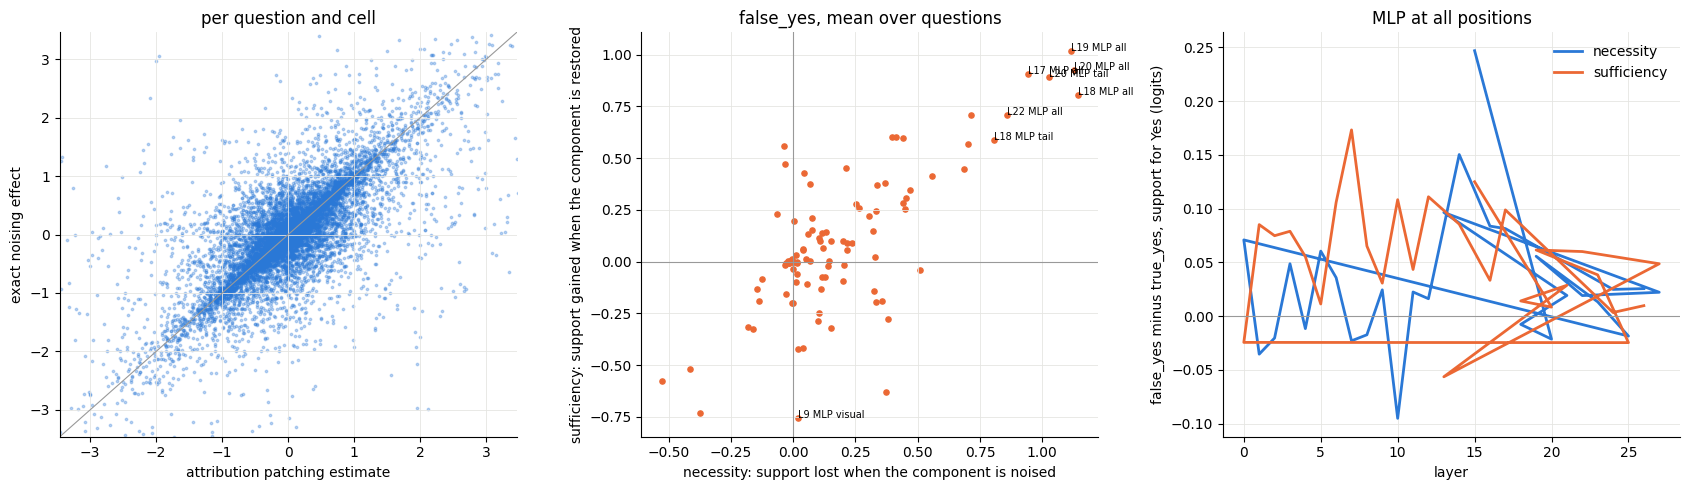

In [6]:
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#999999"
tier = TIERS["full"]
N, A = tier["raw_noising"], tier["atp"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sample = np.random.default_rng(0).choice(N.size, size=min(N.size, 20000), replace=False)
lim = np.percentile(np.abs(np.concatenate([A.ravel()[sample], N.ravel()[sample]])), 99.5)
axes[0].scatter(A.ravel()[sample], N.ravel()[sample], s=3, alpha=0.3, color=BLUE)
axes[0].plot([-lim, lim], [-lim, lim], color=GREY, lw=0.8)
axes[0].set_xlim(-lim, lim)
axes[0].set_ylim(-lim, lim)
axes[0].set_xlabel("attribution patching estimate")
axes[0].set_ylabel("exact noising effect")
axes[0].set_title("per question and cell")
fy = tier["df"].stratum.eq("false_yes").to_numpy()
mn, md = tier["F"]["noising"][fy].mean(0), tier["F"]["denoising"][fy].mean(0)
axes[1].scatter(mn, md, s=14, color=ORANGE)
for i in np.argsort(-np.maximum(np.abs(mn), np.abs(md)))[:8]:
    axes[1].annotate(tier["names"][i], (mn[i], md[i]), fontsize=7)
axes[1].axhline(0, color=GREY, lw=0.8)
axes[1].axvline(0, color=GREY, lw=0.8)
axes[1].set_xlabel("necessity: support lost when the component is noised")
axes[1].set_ylabel("sufficiency: support gained when the component is restored")
axes[1].set_title("false_yes, mean over questions")
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#e8e8e4", ORANGE])
mlp_idx = [i for i, c in enumerate(tier["cells"]) if c["kind"] == "mlp" and c["group"] == "all"]
ct = tier["df"].stratum.eq("true_yes").to_numpy()
if mlp_idx and ct.any():
    layers_ = [tier["cells"][i]["layer"] for i in mlp_idx]
    for direction, color, label in [("noising", BLUE, "necessity"), ("denoising", ORANGE, "sufficiency")]:
        axes[2].plot(layers_, tier["F"][direction][fy][:, mlp_idx].mean(0) - tier["F"][direction][ct][:, mlp_idx].mean(0), color=color, lw=2, label=label)
    axes[2].axhline(0, color=GREY, lw=0.8)
    axes[2].set_xlabel("layer")
    axes[2].set_ylabel("false_yes minus true_yes, support for Yes (logits)")
    axes[2].set_title("MLP at all positions")
    axes[2].legend(frameon=False)
for ax in axes:
    ax.grid(color="#e5e5e2", lw=0.6)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/patching_overview.png", dpi=150)
plt.show()

In [7]:
survivors = {}
tier_name = "focus" if "focus" in TIERS else "full"
for unit in UNITS:
    for cname in SURVIVOR_CONTRASTS:
        pair = both_directions(tier_name, unit, cname)
        if pair is None:
            continue
        rn, rd, both = pair
        for i in np.flatnonzero(both):
            entry = survivors.setdefault(TIERS[tier_name]["names"][int(i)], {"cell": TIERS[tier_name]["cells"][int(i)], "evidence": {}})
            entry["evidence"][f"{unit}/{cname}"] = {"noising": float(rn["m_train"][i]), "denoising": float(rd["m_train"][i])}
print(f"{len(survivors)} cells are material in both directions with the same sign (tier {tier_name}):")
for name, s in sorted(survivors.items(), key=lambda kv: -max(abs(v["noising"]) for v in kv[1]["evidence"].values())):
    print(f"  {name:18s}", {k: (round(v['noising'], 3), round(v['denoising'], 3)) for k, v in s["evidence"].items()})

with open(f"{OUT_DIR}/survivors.json", "w") as f:
    json.dump(survivors, f)

with open(f"{OUT_DIR}/effects.json", "w") as f:
    json.dump({
        f"{tname}/{unit}/{cname}/{direction}": {
            "cells": TIERS[tname]["names"],
            "d_train": r["d_train"].tolist(), "d_val": r["d_val"].tolist(), "d_test": r["d_test"].tolist(),
            "m_train": r["m_train"].tolist(), "m_val": r["m_val"].tolist(), "m_test": r["m_test"].tolist(),
            "material": np.flatnonzero(r["material"]).tolist(), "null95": r["null95"], "n_a": r["n_a"], "n_b": r["n_b"],
        }
        for (tname, unit, cname, direction), r in results.items()
    }, f)

4 cells are material in both directions with the same sign (tier focus):
  L17 MLP all        {'relation/reefknot/matched_driven': (0.155, 0.181)}
  L19 MLP all        {'relation/reefknot/matched_driven': (0.125, 0.097)}
  L18 MLP all        {'relation/reefknot/matched_driven': (0.103, 0.108)}
  L20 MLP tail       {'relation/reefknot/matched_driven': (0.053, 0.098)}


In [8]:
LLAVA_DIR = f"{INPUT}/patch-llava-effects"
LLAVA_LAYERS = 32
if os.path.exists(f"{LLAVA_DIR}/survivors.json"):
    with open(f"{LLAVA_DIR}/survivors.json") as f:
        llava_surv = json.load(f)
    rows = []
    for model_, surv, n_layer_ in [("llava", llava_surv, LLAVA_LAYERS), ("qwen", survivors, N_LAYER)]:
        for name, s in surv.items():
            c = s["cell"]
            rows.append({"model": model_, "cell": name, "kind": c["kind"], "group": c["group"], "layer": c["layer"], "depth": round(c["layer"] / (n_layer_ - 1), 2),
                         "max_noising": round(max(abs(v["noising"]) for v in s["evidence"].values()), 3)})
    cmp_ = pd.DataFrame(rows).sort_values(["model", "depth"])
    print("--- survivors by relative depth (layer divided by the last layer index) ---")
    print(cmp_.to_string(index=False))
    for model_, sub_ in cmp_.groupby("model"):
        mlps_ = sub_[sub_.kind == "mlp"]
        print(f"{model_}: {len(sub_)} survivors, {len(mlps_)} MLP cells at relative depths {sorted(mlps_.depth.unique().tolist())}")
else:
    print("attach patch-llava-effects to compare the survivors across models")

tier = TIERS["focus"] if "focus" in TIERS else TIERS["full"]
d = tier["df"]
for unit in UNITS:
    mask_ = unit_mask(d, unit).to_numpy() & d.te_cls.eq("driven").to_numpy()
    if mask_.sum() < MIN_GROUP:
        print(f"{unit}: {int(mask_.sum())} driven false_yes questions, too few for shares")
        continue
    te_ = d.TE[mask_].mean()
    nec = tier["raw_noising"][mask_].mean(0) / (-te_)
    suf = tier["raw_denoising"][mask_].mean(0) / te_
    order = np.argsort(-np.maximum(np.abs(nec), np.abs(suf)))[:8]
    print(f"--- {unit}: driven false_yes {int(mask_.sum())} questions, mean TE {te_:+.2f}; share of the effect ---")
    print(pd.DataFrame({"cell": [tier["names"][i] for i in order], "necessity": nec[order].round(3), "sufficiency": suf[order].round(3)}).to_string(index=False))

--- survivors by relative depth (layer divided by the last layer index) ---
model         cell kind group  layer  depth  max_noising
llava  L16 MLP all  mlp   all     16   0.52        0.320
llava L16 MLP tail  mlp  tail     16   0.52        0.320
llava  L16 H15 all head   all     16   0.52        0.151
llava L16 H15 tail head  tail     16   0.52        0.140
llava  L17 MLP all  mlp   all     17   0.55        0.142
llava L17 MLP tail  mlp  tail     17   0.55        0.142
llava L18 MLP tail  mlp  tail     18   0.58        0.188
llava  L18 MLP all  mlp   all     18   0.58        0.199
llava  L28 MLP all  mlp   all     28   0.90        0.091
llava L28 MLP tail  mlp  tail     28   0.90        0.092
llava  L31 MLP all  mlp   all     31   1.00        0.050
 qwen  L17 MLP all  mlp   all     17   0.63        0.155
 qwen  L18 MLP all  mlp   all     18   0.67        0.103
 qwen  L19 MLP all  mlp   all     19   0.70        0.125
 qwen L20 MLP tail  mlp  tail     20   0.74        0.053
llava: 11 su

In [9]:
with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": "patch-qwen-effects",
        "id": f"{USERNAME}/patch-qwen-effects",
        "subtitle": "Exact patching effect sizes and surviving components for Qwen2.5-VL",
        "description": "Contrast statistics from patch-qwen-exact. m_* vectors are mean differences in support for Yes (logits) between false_yes and matched true_yes questions, "
                       "d_* vectors Cohen's d, ranked on train, checked on val and reported on test. noising support is minus sign times the change in delta when a component is replaced by its corrupt activation "
                       "(the component's necessary contribution), denoising support is sign times the change when it is restored in the corrupt run (sufficiency). "
                       "Tier full is the complete cell list on the stage A questions, tier focus the cells chosen for stage B on all questions. Contrasts: evidence, evidence_matched (bins of the clean gap), matched_driven. "
                       "effects.json is keyed tier/unit/contrast/direction with the cell names alongside. survivors.json lists cells that are material in both directions with the same sign, the input to path patching.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)

r = subprocess.run(["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", "analysis", "--dir-mode", "zip"], capture_output=True, text=True)
out = (r.stdout + r.stderr).strip()
if r.returncode != 0 or "error" in out.lower():
    r = subprocess.run(["kaggle", "datasets", "create", "-p", OUT_DIR, "--dir-mode", "zip"], capture_output=True, text=True)
    out += "\n" + (r.stdout + r.stderr).strip()
print(out)

Starting upload for file effects.json
Upload successful: effects.json (125KB)
Starting upload for file patching_overview.png
Upload successful: patching_overview.png (377KB)
Starting upload for file survivors.json
Upload successful: survivors.json (806B)
403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/CreateDatasetVersion

  0%|          | 0.00/125k [00:00<?, ?B/s]
100%|██████████| 125k/125k [00:00<00:00, 284kB/s]

  0%|          | 0.00/377k [00:00<?, ?B/s]
100%|██████████| 377k/377k [00:00<00:00, 771kB/s]

  0%|          | 0.00/806 [00:00<?, ?B/s]
100%|██████████| 806/806 [00:00<00:00, 1.81kB/s]
Starting upload for file effects.json
Error while trying to load upload info: KaggleObject.from_dict() got an unexpected keyword argument 'token'
Upload successful: effects.json (125KB)
Starting upload for file patching_overview.png
Error while trying to load upload info: KaggleObject.from_dict() got an unexpected keyword argument 'token'
Upload succes